# Powtórka - uczenie nadzorowane: regresja i klasyfikacja w jednym szkielecie

Poznaliśmy już dwa rodzaje zadań: **regresję** (przewidujemy liczbę - `exam_score`) i **klasyfikację** (przewidujemy klasę - `zdal`). Dzisiaj robimy podsumowanie tych metod uczenia nadzorowanego razem z uzupełnieniem pewnych kwestii.

In [2]:
# Podstawowe biblioteki
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# scikit-learn - wszystkie importy w jednym miejscu
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold,
                                     cross_val_score, cross_val_predict,
                                     validation_curve, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score,
                             ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay)

Wracamy do znanego zbioru o nawykach studentów. Z jednej kolumny `exam_score` zrobimy **dwa** cele:

| Zadanie | Cel | Typ | Pytanie |
|---|---|---|---|
| Regresja | `exam_score` | liczba 0-100 | *Ile punktów zdobędzie ten student?* |
| Klasyfikacja | `zdal` | klasa 0 / 1 | *Czy ten student zda (co najmniej 60 punktów)?* |

In [3]:
df = pd.read_csv("2_student_habits_performance.csv")
df["zdal"] = (df["exam_score"] >= 60).astype(int)

print("Rozmiar:", df.shape)
print("Odsetek zdających:", round(df["zdal"].mean(), 3))
df.head()

Rozmiar: (1000, 17)
Odsetek zdających: 0.72


,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score,zdal
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2,0
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0,1
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3,0
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8,0
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4,1


Zbudujmy pierwszy klasyfikator jak najszybciej: bierzemy **wszystkie kolumny liczbowe** poza celem i uczymy małe drzewo decyzyjne (`max_depth=1` - drzewo może zadać tylko **jedno** pytanie).

In [4]:
# wszystkie kolumny liczbowe oprócz celu
X = df.select_dtypes("number").drop(columns="zdal")
y = df["zdal"]
print("Cechy:", X.columns.tolist())

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                          random_state=42, stratify=y)

drzewko = DecisionTreeClassifier(max_depth=1, random_state=42).fit(X_tr, y_tr)
print("Trafność na teście:", accuracy_score(y_te, drzewko.predict(X_te)))

Cechy: ['age', 'study_hours_per_day', 'social_media_hours', 'netflix_hours', 'attendance_percentage', 'sleep_hours', 'exercise_frequency', 'mental_health_rating', 'exam_score']
Trafność na teście: 1.0


**100% trafności - drzewem, które zadaje jedno pytanie.** Model jest idealny. 

**ZADANIE 1** - Co jest nie tak? Narysuj drzewo w komórce poniżej, a potem odpowiedz w komórce tekstowej pod nią: *o co pyta drzewo i dlaczego to oszustwo?*

In [5]:
# ZADANIE 1 - narysuj drzewo (plot_tree) z nazwami cech i klas
# plt.figure(figsize=(6, 4))
# wykorzystaj funkcje plot_tree
# jej arumentami są: model drzewa, feature_names, class_names, filled=True
# plt.show()

**Rozwiązanie:** drzewo pyta tylko o `exam_score <= 59.95`. Ale `zdal` **powstało** z `exam_score` - model dostał odpowiedź razem z pytaniem. To **wyciek danych** (*data leakage*): w chwili, gdy chcemy przewidzieć, czy student zda, wyniku egzaminu jeszcze **nie znamy**.

### Dwa pytania do każdej kolumny

Zanim wrzucisz kolumnę do `X`, zadaj sobie dwa pytania:
1. **Czy znam tę wartość w chwili przewidywania?** Jeśli nie - to wyciek. (`exam_score` - nie znamy, egzamin dopiero będzie.)
2. **Czy ta cecha może mieć związek z celem z sensownego powodu?** Jeśli nie - model nauczy się szumu na pamięć.

Druga pułapka jest mniej oczywista. Weźmy numer studenta (`student_id`, np. `S1042`) - zamienimy go na liczbę i dodamy do cech. Drzewo tym razem nie ma limitu głębokości.

In [6]:
cechy_num = ["age", "study_hours_per_day", "social_media_hours", "netflix_hours",
             "attendance_percentage", "sleep_hours", "exercise_frequency",
             "mental_health_rating"]

df["numer_studenta"] = df["student_id"].str[1:].astype(int)   # "S1042" -> 1042

X_id = df[cechy_num + ["numer_studenta"]]
X_tr, X_te, y_tr, y_te = train_test_split(X_id, df["zdal"], test_size=0.2,
                                          random_state=42, stratify=df["zdal"])

drzewo_id = DecisionTreeClassifier(random_state=42).fit(X_tr, y_tr)

# Jak bardzo drzewo korzystało z każdej cechy (suma = 1)
waznosc = pd.Series(drzewo_id.feature_importances_, index=X_id.columns)
print(waznosc.sort_values(ascending=False).round(3))

study_hours_per_day      0.532
mental_health_rating     0.097
sleep_hours              0.091
exercise_frequency       0.057
social_media_hours       0.050
attendance_percentage    0.049
netflix_hours            0.048
age                      0.039
numer_studenta           0.037
dtype: float64


**ZADANIE 2** - Numer studenta ma ważność większą od zera, czyli drzewo **używało** go do podejmowania decyzji. Co z tego wynika?

**Rozwiązanie:** numer w legitymacji nie ma nic wspólnego z nauką, a mimo to drzewo oparło na nim część decyzji - **nauczyło się szumu na pamięć**. Na teście wypada przez to gorzej niż takie samo drzewo bez tej kolumny (0.83 zamiast 0.855). Identyfikatory (numery, ID, imiona) nie są cechami.

Podzielmy dane. 
Trik: `train_test_split` przyjmuje **kilka tablic naraz** i dzieli je identycznie - dzięki temu w teście są **ci sami studenci** dla obu zadań. `stratify=y_clf` pilnuje, żeby odsetek zdających był taki sam w treningu i w teście.

In [7]:
X = df[cechy_num]                 # bez exam_score, bez zdal, bez numeru studenta
y_reg = df["exam_score"]          # cel regresji
y_clf = df["zdal"]                # cel klasyfikacji

X_train, X_test, y_reg_train, y_reg_test, y_clf_train, y_clf_test = train_test_split(
    X, y_reg, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

print("Trening:", X_train.shape, "| Test:", X_test.shape)
print("Odsetek zdających - trening:", round(y_clf_train.mean(), 3), "| test:", round(y_clf_test.mean(), 3))

# Foldy do walidacji krzyżowej - te same przez cały notatnik
kfold = KFold(n_splits=5, shuffle=True, random_state=42)             # regresja
skfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)  # klasyfikacja

Trening: (800, 8) | Test: (200, 8)
Odsetek zdających - trening: 0.72 | test: 0.72


## 1. Baseline

Model, który **niczego się nie nauczył**, to punkt odniesienia. Jeśli nasz model go wyraźnie nie bije - coś jest nie tak.
- regresja: `DummyRegressor` - zawsze przewiduje **średnią** z treningu,
- klasyfikacja: `DummyClassifier(strategy="most_frequent")` - zawsze przewiduje **najczęstszą klasę**.

In [44]:
dummy_reg = DummyRegressor(strategy="mean")

# sklearn zawsze MAKSYMALIZUJE wynik, więc błędy podaje ze znakiem minus -
# stąd "neg_" w nazwie i minus przed wywołaniem
mae_dummy = -cross_val_score(dummy_reg, X_train, y_reg_train, cv=kfold,
                             scoring="neg_mean_absolute_error").mean()
print(f"Baseline regresji - MAE: {mae_dummy:.2f} pkt")

Baseline regresji - MAE: 13.92 pkt


In [ ]:
# ZADANIE 3 - utwórz DummyClassifier(strategy="most_frequent") i policz jego średnią
#             trafność w walidacji krzyżowej (cv=skfold, scoring="accuracy")


# print(f"Baseline klasyfikacji - trafność (accuracy): {acc_dummy:.3f}")

Baseline klasyfikacji - trafność: 0.720


**Model, który zawsze mówi „zda”, ma 72% trafności - nie umiejąc niczego.** Zapamiętaj tę liczbę: każdą trafność w tym zadaniu porównujemy z nią, a nie z zerem.

## 2. Pipeline

`Pipeline` łączy przygotowanie danych i model w jeden obiekt (ostatnie zajęcia). Na razie przygotowanie to tylko skalowanie - uczone wyłącznie na treningu, bo siedzi w środku pipeline'u.

In [10]:
# Pipeline REGRESJI: skalowanie + model regresji
pipe_reg = Pipeline([
    ("skaler", StandardScaler()),
    ("model", LinearRegression()),
])
pipe_reg

Pipeline(steps=[('skaler', StandardScaler()), ('model', LinearRegression())])

**ZADANIE 4** - zbuduj `pipe_clf` - pipeline **klasyfikacji**. Przygotowanie danych jest identyczne; zmienia się tylko model na końcu: `LogisticRegression(max_iter=5000)`.

In [ ]:
# ZADANIE 4 - zbuduj pipe_clf: to samo przygotowanie + LogisticRegression(max_iter=5000)


Pipeline(steps=[('skaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=5000))])

## 3. Walidacja krzyżowa

Ta sama procedura co w lekcji 5 - tym razem dla obu zadań, w porównaniu z baseline'em.

In [45]:
mae_cv = -cross_val_score(pipe_reg, X_train, y_reg_train, cv=kfold,
                          scoring="neg_mean_absolute_error")
r2_cv = cross_val_score(pipe_reg, X_train, y_reg_train, cv=kfold, scoring="r2")

print(f"REGRESJA      MAE: {mae_cv.mean():.2f} pkt (baseline: {mae_dummy:.2f})  |  R^2: {r2_cv.mean():.3f}")

REGRESJA      MAE: 4.30 pkt (baseline: 13.92)  |  R^2: 0.899


In [ ]:
# ZADANIE 5 - policz w walidacji krzyżowej (cv=skfold) trafność pipe_clf (scoring="accuracy")
#             oraz F1 (scoring="f1")

# print(f"KLASYFIKACJA  trafność: {acc_cv.mean():.3f} (baseline: {acc_dummy:.3f})  |  F1: {f1_cv.mean():.3f}")

KLASYFIKACJA  trafność: 0.924 (baseline: 0.720)  |  F1: 0.948


Oba modele wyraźnie biją baseline. Ale **jedna liczba to nie wszystko** - zobaczmy, *gdzie* modele się mylą.

## 4. Wykres obok liczby

Narysujemy wykresy **bez dotykania zbioru testowego**, używając `cross_val_predict`. Dla każdego studenta z treningu dostajemy przewidywanie modelu, który **nie widział go** podczas nauki (bo ten student był akurat w foldzie walidacyjnym).

### Regresja: przewidywane vs rzeczywiste

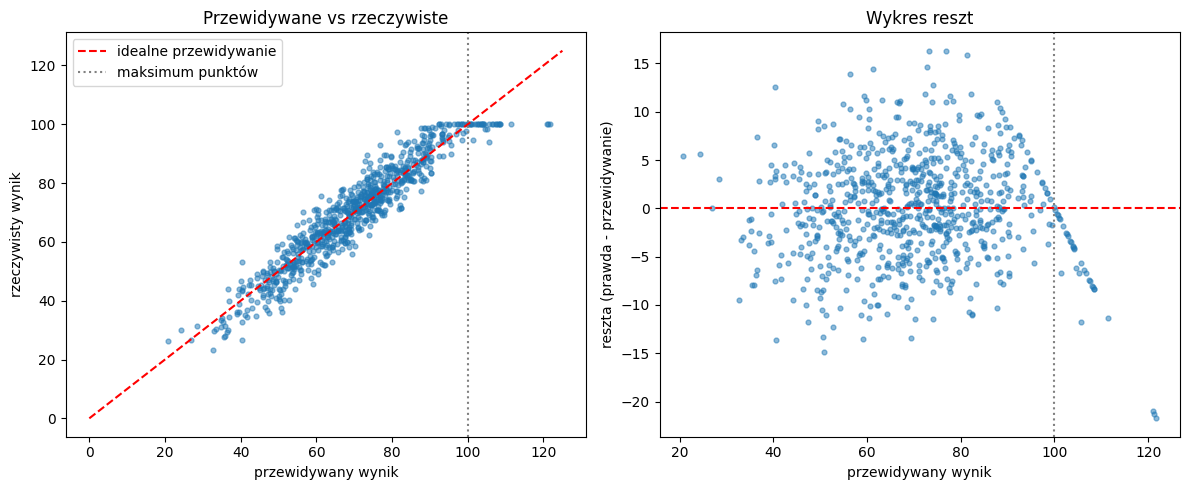

In [46]:
y_reg_oof = cross_val_predict(pipe_reg, X_train, y_reg_train, cv=kfold)
reszty = y_reg_train - y_reg_oof            # reszta = prawda - przewidywanie

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.scatter(y_reg_oof, y_reg_train, s=12, alpha=0.5)
ax1.plot([0, 125], [0, 125], color="red", linestyle="--", label="idealne przewidywanie")
ax1.axvline(100, color="gray", linestyle=":", label="maksimum punktów")
ax1.set_xlabel("przewidywany wynik")
ax1.set_ylabel("rzeczywisty wynik")
ax1.set_title("Przewidywane vs rzeczywiste")
ax1.legend()

ax2.scatter(y_reg_oof, reszty, s=12, alpha=0.5)
ax2.axhline(0, color="red", linestyle="--")
ax2.axvline(100, color="gray", linestyle=":")
ax2.set_xlabel("przewidywany wynik")
ax2.set_ylabel("reszta (prawda - przewidywanie)")
ax2.set_title("Wykres reszt")

plt.tight_layout()
plt.show()

**ZADANIE 6** - Przyjrzyj się prawej części obu wykresów. Co jest nie tak z przewidywaniami dla najlepszych studentów? Policz w komórce poniżej, ile przewidywań przekracza 100 punktów i jakie jest największe.

In [ ]:
# ile przewidywań (y_reg_oof) przekracza 100 i jaka jest największa wartość
print("Przewidywań powyżej 100:", (y_reg_oof > 100).sum())
print("Największe przewidywanie:", y_reg_oof.max().round(1))

Przewidywań powyżej 100: 32
Największe przewidywanie: 121.7


**Rozwiązanie:** model liniowy nie wie, że skala kończy się na 100. Dla studentów, którzy dużo się uczą, przewiduje nawet ponad 120 punktów. Na lewym wykresie widać to jako poziomy „sufit” punktów na wysokości 100, który ciągnie się daleko w prawo. Na wykresie reszt - jako opadającą linię poniżej zera po prawej stronie. **MAE tego nie pokazało** - to jedna liczba uśredniona po wszystkich studentach.

Wykres od razu podpowiada prostą poprawkę: przyciąć przewidywania do zakresu 0-100.

In [48]:
mae_przed = mean_absolute_error(y_reg_train, y_reg_oof)
mae_po = mean_absolute_error(y_reg_train, np.clip(y_reg_oof, 0, 100))
print(f"MAE bez przycinania: {mae_przed:.2f} | po przycięciu do 0-100: {mae_po:.2f}")

MAE bez przycinania: 4.30 | po przycięciu do 0-100: 4.05


Poprawa jest niewielka, ale darmowa - i przede wszystkim model przestaje przewidywać rzeczy niemożliwe. Przycinanie zastosujemy w teście i przy zapisie modelu.

### Klasyfikacja: rozkład prawdopodobieństw

In [49]:
p_oof = cross_val_predict(pipe_clf, X_train, y_clf_train, cv=skfold, method="predict_proba")
p_zdal = p_oof[:, 1]        # kolumna 1 = prawdopodobieństwo klasy 1, czyli "zdał"

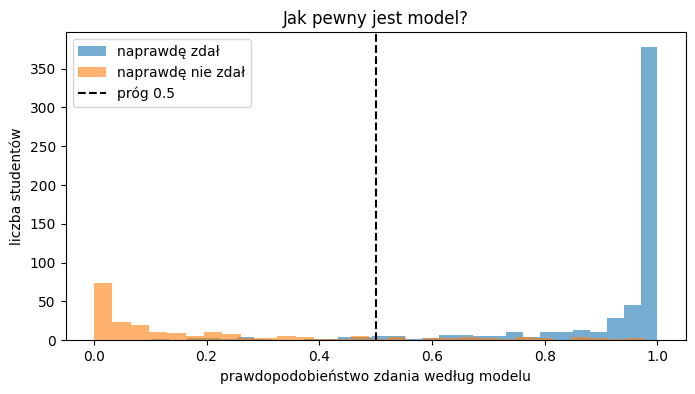

In [50]:
plt.figure(figsize=(8, 4))
plt.hist(p_zdal[y_clf_train == 1], bins=30, alpha=0.6, label="naprawdę zdał")
plt.hist(p_zdal[y_clf_train == 0], bins=30, alpha=0.6, label="naprawdę nie zdał")
plt.axvline(0.5, color="black", linestyle="--", label="próg 0.5")
plt.xlabel("prawdopodobieństwo zdania według modelu")
plt.ylabel("liczba studentów")
plt.title("Jak pewny jest model?")
plt.legend()
plt.show()

Większość studentów model ocenia pewnie (słupki przy 0 i przy 1). Kłopot jest pośrodku, tam gdzie oba kolory się nakładają. **To, gdzie postawimy próg, decyduje o tym, kogo pomylimy.**

## 5. Próg decyzyjny i krzywa ROC

Idealna szkoła chce **wyłapać studentów zagrożonych**, żeby zaproponować im pomoc. Dla niej ważniejsza jest klasa **"nie zda"**:
- przeoczony zagrożony student (nie dostanie pomocy) - **poważny** błąd,
- fałszywy alarm (pomoc dla kogoś, kto i tak by zdał) - też błąd, ale **tani**.

Zamiast pytać "czy zda?", pytamy więc "czy podnieść alarm?". Alarm podnosimy, gdy **ryzyko** (prawdopodobieństwo, że student nie zda) przekroczy próg.

W lekcji 4 próg był zawsze równy 0.5. Ale **próg to decyzja, a nie stała** - zobaczmy, co się dzieje, gdy go przesuwamy.

In [19]:
ryzyko = 1 - p_zdal                 # prawdopodobieństwo, że NIE zda
zagrozony = 1 - y_clf_train         # 1 = naprawdę nie zdał

wiersze = []
for prog in [0.5, 0.4, 0.3, 0.25, 0.2, 0.15, 0.1]:
    alarm = (ryzyko >= prog).astype(int)
    wiersze.append({
        "próg": prog,
        "recall (wyłapani zagrożeni)": recall_score(zagrozony, alarm),
        "precision (trafne alarmy)": precision_score(zagrozony, alarm),
        "liczba alarmów": alarm.sum(),
        "przeoczeni": ((alarm == 0) & (zagrozony == 1)).sum(),
    })

print("Zagrożonych w treningu:", zagrozony.sum())
pd.DataFrame(wiersze).round(3)

Zagrożonych w treningu: 224


,próg,recall (wyłapani zagrożeni),precision (trafne alarmy),liczba alarmów,przeoczeni
0,0.50,0.835,0.886,211,37
1,0.40,0.853,0.834,229,33
2,0.30,0.902,0.771,262,22
3,0.25,0.920,0.749,275,18
4,0.20,0.946,0.721,294,12
5,0.15,0.955,0.684,313,10
6,0.10,0.978,0.648,338,5


**Kompromis:** niższy próg daje więcej wyłapanych zagrożonych (recall rośnie), ale też więcej fałszywych alarmów (precision spada). Nie ma progu "najlepszego w ogóle" - jest najlepszy **dla konkretnego celu**.

### Krzywa ROC i AUC

Krzywa ROC pokazuje **wszystkie progi naraz** - każdy punkt krzywej to jeden próg:
- oś X - jaka część **niezagrożonych** dostała fałszywy alarm,
- oś Y - jaka część **zagrożonych** została wyłapana (recall).

**AUC** (pole pod krzywą) podsumowuje ją jedną liczbą: 0.5 = rzut monetą, 1.0 = model idealny. Można ją czytać tak: *jeśli wylosujemy jednego zagrożonego i jednego niezagrożonego studenta, AUC to szansa, że model da zagrożonemu wyższe ryzyko.*

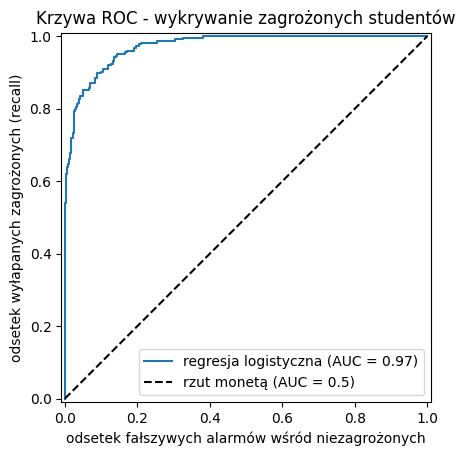

AUC: 0.973


In [20]:
RocCurveDisplay.from_predictions(zagrozony, ryzyko, name="regresja logistyczna",
                                 plot_chance_level=True,
                                 chance_level_kw={"label": "rzut monetą (AUC = 0.5)"})
plt.xlabel("odsetek fałszywych alarmów wśród niezagrożonych")
plt.ylabel("odsetek wyłapanych zagrożonych (recall)")
plt.title("Krzywa ROC - wykrywanie zagrożonych studentów")
plt.legend(loc="lower right")
plt.show()

print("AUC:", round(roc_auc_score(zagrozony, ryzyko), 3))

## 6. Przeuczenie w obu zadaniach naraz

Drzewo decyzyjne bez limitu głębokości potrafi „nauczyć się na pamięć” każdego studenta z treningu. Sprawdźmy to w obu zadaniach.

In [51]:
drzewo_reg = Pipeline([("skaler", StandardScaler()),
                       ("model", DecisionTreeRegressor(random_state=42))])
drzewo_clf = Pipeline([("skaler", StandardScaler()),
                       ("model", DecisionTreeClassifier(random_state=42))])

drzewo_reg.fit(X_train, y_reg_train)
drzewo_clf.fit(X_train, y_clf_train)

r2_trening = r2_score(y_reg_train, drzewo_reg.predict(X_train))
r2_walidacja = cross_val_score(drzewo_reg, X_train, y_reg_train, cv=kfold, scoring="r2").mean()
acc_trening = accuracy_score(y_clf_train, drzewo_clf.predict(X_train))
acc_walidacja = cross_val_score(drzewo_clf, X_train, y_clf_train, cv=skfold).mean()

print(f"REGRESJA      R² - trening: {r2_trening:.3f} | walidacja krzyżowa: {r2_walidacja:.3f}")
print(f"KLASYFIKACJA  trafność - trening: {acc_trening:.3f} | walidacja krzyżowa: {acc_walidacja:.3f}")

REGRESJA      R² - trening: 1.000 | walidacja krzyżowa: 0.676
KLASYFIKACJA  trafność - trening: 1.000 | walidacja krzyżowa: 0.840


Idealny wynik na treningu, wyraźnie gorszy na nowych danych - to **przeuczenie**. Krzywa walidacji pokaże, jak zmienia się to razem z głębokością drzewa:

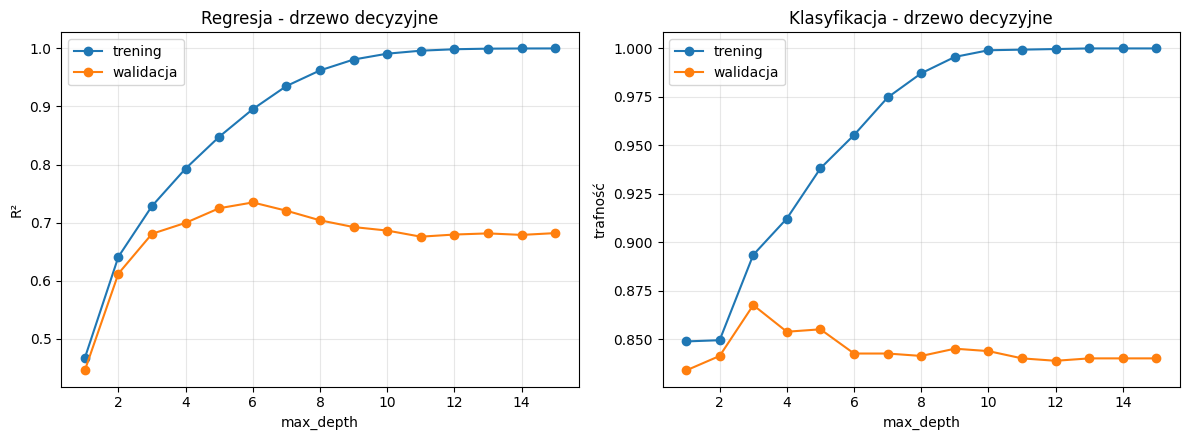

In [52]:
glebokosci = range(1, 16)

tr_reg, wal_reg = validation_curve(drzewo_reg, X_train, y_reg_train,
                                   param_name="model__max_depth", param_range=glebokosci,
                                   cv=kfold, scoring="r2")
tr_clf, wal_clf = validation_curve(drzewo_clf, X_train, y_clf_train,
                                   param_name="model__max_depth", param_range=glebokosci,
                                   cv=skfold, scoring="accuracy")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, tr, wal, tytul, metryka in [(ax1, tr_reg, wal_reg, "Regresja", "R²"),
                                     (ax2, tr_clf, wal_clf, "Klasyfikacja", "trafność")]:
    ax.plot(glebokosci, tr.mean(axis=1), marker="o", label="trening")
    ax.plot(glebokosci, wal.mean(axis=1), marker="o", label="walidacja")
    ax.set_title(f"{tytul} - drzewo decyzyjne")
    ax.set_xlabel("max_depth")
    ax.set_ylabel(metryka)
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

### Jak czytać te wykresy - kompromis bias-variance

Niebieska linia to wynik na danych, na których drzewo się uczyło, pomarańczowa - na danych, których nie widziało. Liczy się **pomarańczowa**: to ona mówi, jak model poradzi sobie z nowymi studentami.

- **Niska głębokość - model za prosty** (*duży bias*, niedouczenie). Drzewo zadaje 1-2 pytania, np. tylko „ile godzin dziennie się uczysz?”. Obie linie są nisko i blisko siebie: model myli się tak samo na starych i nowych danych, bo jest za prosty, żeby uchwycić zależności.
- **Większe głębokości - model za złożony** (*duża wariancja*, przeuczenie). Niebieska linia dochodzi do 1.0 - drzewo zapamiętało każdego studenta z treningu. Pomarańczowa przestaje rosnąć, a nawet lekko spada. **Najważniejszy sygnał przeuczenia to rosnąca przerwa między liniami**: model coraz lepiej zna trening, ale nie staje się przez to lepszy na nowych danych.

**ZADANIE** - Odczytaj z wykresów najlepszą głębokość dla regresji i dla klasyfikacji. Czy to ta sama wartość? Co z tego wynika?

**Rozwiązanie:** regresja - 6, klasyfikacja - 3. Najlepsze ustawienie zależy od zadania, nawet na tych samych danych. Dlatego hiperparametrów nie przepisujemy z innego projektu, tylko za każdym razem je stroimy.

## 7. Strojenie

`GridSearchCV` znamy z poprzednich zajęć. Teraz wprowadzimy nowość: w siatce można podmieniać **cały model** - to możliwe właśnie dlatego, że pipeline ma krok o nazwie `"model"`. Sprawdzimy trzy rodziny modeli dla regresji.

Metrykę wybieramy świadomie: `neg_mean_absolute_error` - średni błąd w punktach (z minusem, bo sklearn zawsze szuka maksimum).

In [24]:
siatka_reg = [
    {"model": [LinearRegression()]},
    {"model": [KNeighborsRegressor()], "model__n_neighbors": [5, 15, 30]},
    {"model": [DecisionTreeRegressor(random_state=42)], "model__max_depth": [3, 6, 9]},
]
szukaj_reg = GridSearchCV(pipe_reg, siatka_reg, cv=kfold, scoring="neg_mean_absolute_error")
szukaj_reg.fit(X_train, y_reg_train)

print("Najlepszy model regresji:", szukaj_reg.best_params_)
print(f"MAE w walidacji krzyżowej: {-szukaj_reg.best_score_:.2f} pkt")

Najlepszy model regresji: {'model': LinearRegression()}
MAE w walidacji krzyżowej: 4.30 pkt


Wygrał najprostszy, **liniowy** model - to częsty wynik na danych tabelarycznych i dobry powód, żeby zawsze sprawdzać go jako pierwszy.

Dla klasyfikacji zostajemy przy regresji logistycznej z `pipe_clf` - to dla niej dobraliśmy próg alarmu. **Próg należy do konkretnego modelu**: gdybyśmy zmienili model, próg trzeba by dobrać od nowa.

## 8. Zapis modelu do pliku

Uczenie modelu wymaga danych i czasu. **Używanie** go - już nie. Dlatego w praktyce te dwie rzeczy się rozdziela:
- **notatnik** - tu model powstaje: dane, eksperymenty, strojenie, a na końcu **plik z modelem**,
- **program** (aplikacja, strona, gra) - tylko **wczytuje plik** i woła `predict`.

Tak samo zrobimy w naych projektach: modele regresji i klasyfikacji nauczymy w notatnikach, a gra będzie je jedynie wczytywać.

### Co trzeba zapisać?

Nie sam model, tylko **wszystko, czego program potrzebuje, żeby użyć go poprawnie**:

| Co | Dlaczego |
|---|---|
| cały **pipeline** (przygotowanie + model) | program nie musi wiedzieć, jak skalować dane - pipeline zrobi to sam |
| **lista cech** | program musi wiedzieć, jakie dane podać |
| **próg** decyzji | to też część „modelu” - wybraliśmy go w sekcji 5 |
| **wersja scikit-learn** | plik wczytany w innej wersji może działać źle albo wcale |
| wyniki z testu | żeby za miesiąc wiedzieć, jak dobry był ten model |

Wszystko to pakujemy w jeden słownik i zapisujemy biblioteką `joblib` (instaluje się razem ze scikit-learn).

In [27]:
import joblib
import sklearn
from pathlib import Path

Path("modele").mkdir(exist_ok=True)         # folder na modele

paczka_clf = {
    "pipeline": najlepszy_clf,
    "cechy": cechy_num,
    "prog_alarmu": PROG,
    "opis": "Ryzyko, że student nie zda egzaminu (alarm, gdy ryzyko >= prog_alarmu)",
    "wersja_sklearn": sklearn.__version__,
    "wyniki_test": {"auc": round(roc_auc_score(zagrozony_test, ryzyko_test), 3),
                    "recall": round(recall_score(zagrozony_test, alarm_test), 3)},
}

joblib.dump(paczka_clf, "modele/model_zagrozenia.joblib")
print("Zapisano plik:", Path("modele/model_zagrozenia.joblib").stat().st_size // 1024, "KB")

Zapisano plik: 2 KB


### Wczytanie - tak, jakby robił to inny program

In [28]:
wczytana = joblib.load("modele/model_zagrozenia.joblib")

print("Opis:", wczytana["opis"])
print("Wersja sklearn przy zapisie:", wczytana["wersja_sklearn"], "| teraz:", sklearn.__version__)

# Czy wczytany model przewiduje DOKŁADNIE to samo co oryginał?
p_oryginal = najlepszy_clf.predict_proba(X_test)
p_wczytany = wczytana["pipeline"].predict_proba(X_test)
print("Identyczne przewidywania:", np.allclose(p_oryginal, p_wczytany))

Opis: Ryzyko, że student nie zda egzaminu (alarm, gdy ryzyko >= prog_alarmu)
Wersja sklearn przy zapisie: 1.6.1 | teraz: 1.6.1
Identyczne przewidywania: True


### Użycie poza notatnikiem


In [ ]:
skrypt = '''\
from pathlib import Path
import joblib
import pandas as pd

# Ścieżka względem TEGO pliku, a nie miejsca, z którego uruchamiamy program -
# dzięki temu skrypt (albo gra) znajdzie model niezależnie od tego, skąd go odpalimy.
FOLDER = Path(__file__).parent
paczka = joblib.load(FOLDER / "model_zagrozenia.joblib")   # wczytujemy RAZ, przy starcie

def ocen_studenta(dane_studenta):
    # kolumny w tej samej kolejności co przy nauce; brak którejś cechy -> czytelny błąd
    wiersz = pd.DataFrame([dane_studenta])[paczka["cechy"]]
    ryzyko = 1 - paczka["pipeline"].predict_proba(wiersz)[0, 1]
    return ryzyko, ryzyko >= paczka["prog_alarmu"]


student = {"age": 20, "study_hours_per_day": 1.0, "social_media_hours": 4.0, "netflix_hours": 4.0,
           "attendance_percentage": 70, "sleep_hours": 5.0, "exercise_frequency": 1,
           "mental_health_rating": 4}
ryzyko, alarm = ocen_studenta(student)
print(f"Ryzyko niezdania: {ryzyko:.2f} -> {'ALARM' if alarm else 'OK'}")
'''

Path("modele/przewiduj.py").write_text(skrypt, encoding="utf-8")
print("Zapisano skrypt modele/przewiduj.py")

Zapisano skrypt modele/przewiduj.py



### Jak przeniesiemy to do gry

- Model wczytujemy **raz**, przy starcie gry - nie w pętli `while running`, która wykonuje się 60 razy na sekundę.
- `predict` wołamy wtedy, gdy coś się zmieniło (np. dron wleciał na nowe pole), a nie w każdej klatce.
- Gra musi mieć zainstalowaną **tę samą wersję scikit-learn**, co notatnik - dlatego zapisujemy ją w paczce.
- Gra musi podać **wszystkie** cechy z listy `paczka["cechy"]` - jeśli którejś zabraknie, pandas zgłosi błąd z nazwami brakujących kolumn.
- Plik modelu kopiujemy do folderu gry i szukamy go przez `Path(__file__).parent`, jak w skrypcie powyżej.

## Podsumowanie

- **Regresja i klasyfikacja to ten sam szkielet** - zmienia się tylko model na końcu i metryka.
- **Wyciek danych** potrafi wyglądać jak sukces: 100% trafności to sygnał alarmowy, a nie powód do radości. Przy każdej cesze pytaj: *czy znam ją w chwili przewidywania?*
- **Identyfikatory to nie cechy** - model nauczy się ich na pamięć.
- **Wykres pokazuje to, czego nie pokaże liczba** - np. przewidywanie 120 punktów na 100 możliwych.
- **Próg to decyzja**, dobierana do celu (np. wyłapać 90% zagrożonych) - na treningu, nie na teście.
- **Przeuczenie** wygląda tak samo w obu zadaniach; najlepsza złożoność leży między „za prosto” a „za złożenie” (**bias-variance**).
- **Test oglądamy raz**, na samym końcu.
- **Model zapisujemy razem z tym, czego potrzebuje program**: pipeline, lista cech, próg, wersja scikit-learn. Program wczytuje plik raz, przy starcie.


### Metryki - kiedy której używać

| Zadanie | Metryka | Co mówi | Kiedy używać | Uwaga |
|---|---|---|---|---|
| Regresja | **MAE** | średni błąd w jednostkach celu (np. w punktach) | gdy wynik ma być zrozumiały dla każdego | wszystkie błędy traktuje tak samo |
| Regresja | **RMSE** | błąd, który mocniej karze duże pomyłki | gdy duże pomyłki są szczególnie groźne | wrażliwa na wartości odstające |
| Regresja | **R²** | jaką część zmienności celu wyjaśnia model (1 = idealnie, 0 = jak zgadywanie średniej) | do porównywania modeli na tych samych danych | może być ujemne; nie mówi, *jak duże* są błędy |
| Klasyfikacja | **trafność** (accuracy) | odsetek poprawnych odpowiedzi | gdy klasy są mniej więcej równe | przy nierównych klasach kłamie - porównuj z baseline'em |
| Klasyfikacja | **precision** | jaka część alarmów była trafna | gdy fałszywy alarm jest kosztowny (np. filtr spamu kasujący ważne maile) | zależy od progu |
| Klasyfikacja | **recall** | jaką część ważnych przypadków wyłapaliśmy | gdy przeoczenie jest kosztowne (choroba, zagrożony uczeń, pożar) | zależy od progu |
| Klasyfikacja | **F1** | precision i recall w jednej liczbie | gdy oba rodzaje błędów są ważne | zależy od progu |
| Klasyfikacja | **ROC AUC** | jak dobrze model porządkuje przypadki od najbardziej do najmniej prawdopodobnych | do porównywania modeli, zanim wybierzemy próg | nie zależy od progu |
